In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy as sp
from scipy.odr import *
import random
import operator
import os
import seaborn as sns
from mpl_toolkits.mplot3d import axes3d

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [2]:
plt.rcParams['figure.facecolor'] = 'w'
plt.rcParams['figure.edgecolor'] = 'k'

In [3]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
MdotDustIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
HIndex=15 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
FourPointFiveIndex=18 # Column of imported files that has 3.6 band magnitude
FivePointEightIndex=19 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data

In [4]:
def linear_fit_1var (xdata, ydata):
    x = xdata
    y = ydata
    
    data = pandas.DataFrame({'x': x, 'y': y})
    model = ols("y ~ x", data).fit()
    # Parameters are returned in the format intercept, slope
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params

def multilinear_fit_2var (xdata, ydata):
    x0 = xdata[0]
    x1 = xdata[1]
    y = ydata
    
    data = pandas.DataFrame({'x0': x0, 'x1': x1, 'y': y})
    model = ols("y ~ x0 + x1", data).fit()
    
    # Parameters are returned in the format intercept, slope 1, slope 2
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params

In [5]:
def calc_kappa_crit (StarData):
    MData = StarData[MIndex]
    LData = StarData[LIndex]
    MData_CGS = MData*1.989e33 # Convert solar masses to grams
    LData_CGS = LData*3.826e33 # Convert solar lums. to erg s^-1
    c_CGS = 2.998e10 # Speed of light in cm/s
    G_CGS = 6.6743e-8 # Gravitational constant in cm^3 g^-1 s^-2
    kappa_crit = 4*np.pi*c_CGS*G_CGS*MData_CGS/LData_CGS
    return kappa_crit

In [6]:
kappa_crit_M0 = calc_kappa_crit (M0StarData)
kappa_crit_M1 = calc_kappa_crit (M1StarData)
kappa_crit_C0 = calc_kappa_crit (C0StarData)
kappa_crit_C1 = calc_kappa_crit (C1StarData)

In [41]:
def kappa_analysis (StarData):
    MData = StarData[MIndex]
    LData = StarData[LIndex]
    MData_CGS = MData*1.989e33 # Convert solar masses to grams
    LData_CGS = LData*3.826e33 # Convert solar lums. to erg s^-1
    c_CGS = 2.998e10 # Speed of light in cm/s
    G_CGS = 6.6743e-8 # Gravitational constant in cm^3 g^-1 s^-2
    kappa_crit = 4*np.pi*c_CGS*G_CGS*MData_CGS/LData_CGS
    mean_kappa = np.nanmean(kappa_crit)
    print(u'<\u03BA> =',mean_kappa)
    max_kappa = np.nanmax(kappa_crit)
    print(u'Max. \u03BA =',max_kappa)
    min_kappa = np.nanmin(kappa_crit)
    print(u'Min. \u03BA =',min_kappa)
    
    # Color-map of kappa in logM v logL
    plt.scatter(np.log10(LData), np.log10(MData),c=kappa_crit,s=4)
    plt.colorbar(label=r'$\kappa_{\mathrm{crit.}}$')
    plt.xlabel(r'$\log L$')
    plt.ylabel(r'$\log M$')
    plt.show()
    plt.close()
    
    # Plot of kappa vs dust Mdot
    plt.scatter(np.log10(StarData[MdotDustIndex]),kappa_crit,s=4)
    plt.xlabel(r'$\log \dot{M}_{\mathrm{Dust}}$')
    plt.ylabel(r'$\kappa_{\mathrm{crit.}}$')
    plt.show()
    plt.close()

M0:
<κ> = 4.086843480555037
Max. κ = 6.572847970729464
Min. κ = 2.3902367482186704


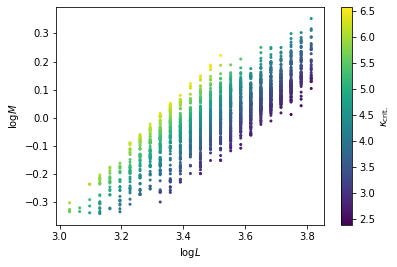

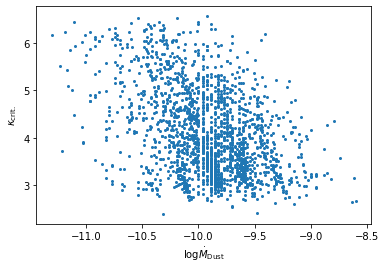

M1:
<κ> = 3.6271726621412475
Max. κ = 8.149617052433095
Min. κ = 1.0829871813860905


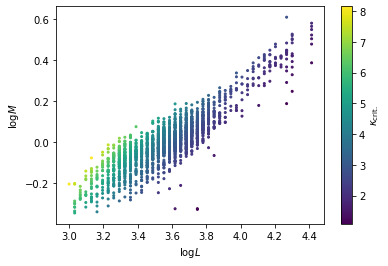

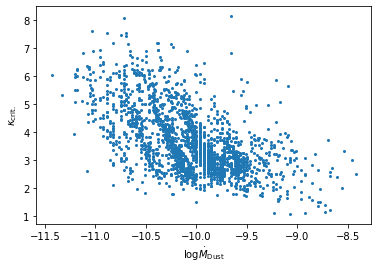

C0:
<κ> = 3.0592579458294495
Max. κ = 5.046220357408512
Min. κ = 1.6155250151063743


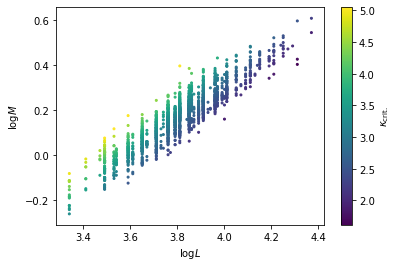

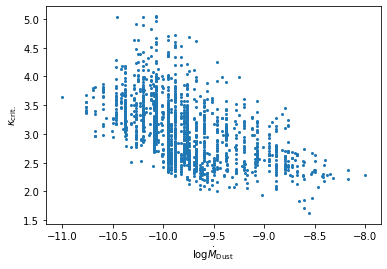

C1:
<κ> = 2.639927149194619
Max. κ = 4.2990531554173215
Min. κ = 0.8734326886854518


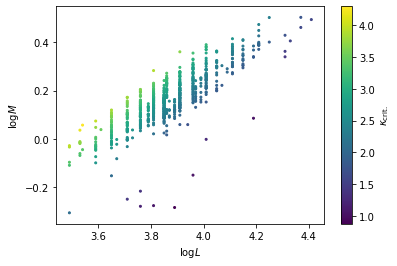

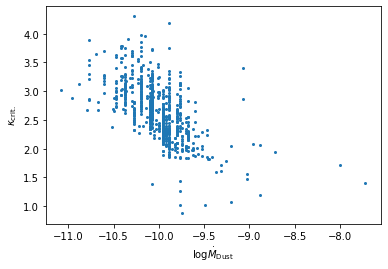

In [42]:
print('M0:')
kappa_analysis(M0StarData)
print('M1:')
kappa_analysis(M1StarData)
print('C0:')
kappa_analysis(C0StarData)
print('C1:')
kappa_analysis(C1StarData)

In [ ]:
MData_CGS = 1*1.989e33 # Convert solar masses to grams
LData_CGS = 7000*3.826e33 # Convert solar lums. to erg s^-1
c_CGS = 2.998e10 # Speed of light in cm/s
G_CGS = 6.6743e-8 # Gravitational constant in cm^3 g^-1 s^-2
kappa_crit = 4*np.pi*c_CGS*G_CGS*MData_CGS/LData_CGS
print((10**0.42)*kappa_crit)